In [1]:
import sys 
sys.path.append('../src')

from data_processing.load import load_and_preprocess_data
from models.model import WindPowerModel

import jax.numpy as jnp

import torch
from torch import nn, optim
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt




### Load data and preprocess
- wind direction transformed from degree using sin and cos
- select one bid zone
- include UMM downtime data
- calculate capacity factor
- scale input features and meta data

Shapes:
- X: (timestamps, wind parks, features)
- Y: (timestamps)
- sites_meta: (wind parks, 1)

In [2]:
from operator import itemgetter
data = load_and_preprocess_data()
(X_train, X_test, Y_train_gen, Y_test_gen,
 Y_train_cf, Y_test_cf, Y_train_aval, Y_test_aval,
 sites_meta, feature_cols) = itemgetter(
    "X_train","X_test","Y_train_gen","Y_test_gen",
    "Y_train_cf","Y_test_cf","Y_train_aval","Y_test_aval",
    "sites_meta","feature_cols"
)(data)


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:59: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Preprocessing done. X_train shape: (19130, 6, 6)
Preprocessing done. X_test shape: (2161, 6, 6)


### Classic NN 
- shared weights for all parks
- wind park specific embeddings (max_operational_power as input) with embed_dim

In [3]:
X_train_tensor = torch.tensor(X_train)
Y_train_cf_tensor = torch.tensor(Y_train_cf)
Y_train_gen_tensor = torch.tensor(Y_train_gen)
X_test_tensor = torch.tensor(X_test)
Y_test_cf_tensor = torch.tensor(Y_test_cf)
sites_meta_tensor = torch.tensor(sites_meta, dtype=torch.float32)

In [7]:
_, num_windparks, num_features = X_train_tensor.shape

In [8]:
nn_model = WindPowerModel(num_windparks, num_features, 3, sites_meta.shape[1])

optimizer = optim.Adam(nn_model.parameters(), lr=1e-3)
criterion = nn.MSELoss()


for step in range(3000):
    nn_model.train()
    optimizer.zero_grad()
    y_site_pred, y_sum_pred = nn_model(X_train_tensor, sites_meta_tensor)

    loss = criterion(y_sum_pred, Y_train_gen_tensor)
    
    loss.backward()
    optimizer.step()
    
    if step % 250 == 0:
        print(f"Step {step:3d} | Loss: {loss.item():.4f}")


Step   0 | Loss: 20845.6367
Step 250 | Loss: 7555.7554
Step 500 | Loss: 4282.0552
Step 750 | Loss: 3645.1099
Step 1000 | Loss: 3473.3481
Step 1250 | Loss: 3327.4729
Step 1500 | Loss: 3230.7825
Step 1750 | Loss: 3167.9109
Step 2000 | Loss: 3118.5146
Step 2250 | Loss: 3074.3267
Step 2500 | Loss: 3030.9070
Step 2750 | Loss: 2985.0774


In [10]:
nn_model.eval()
with torch.no_grad():
    y_site_pred, y_sum_pred = nn_model(X_test_tensor, sites_meta_tensor)

# Rescale to generation prediction
Y_pred = y_sum_pred.numpy() #* Y_test_aval
mse = mean_squared_error(Y_test_gen, Y_pred)
rmse = jnp.sqrt(mse)


print(f"Evaluation metrics:")
print(f"RMSE: {rmse:.2f} MW")



Evaluation metrics:
RMSE: 71.31 MW


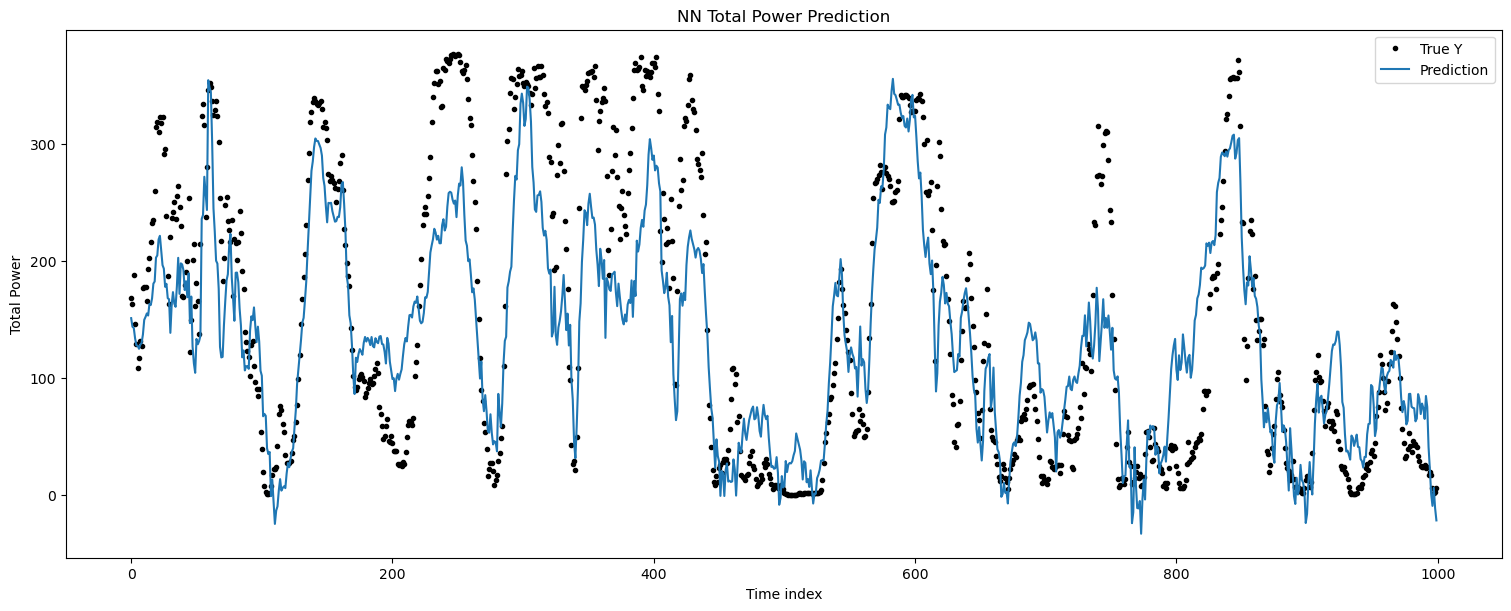

In [11]:
# Plot
n_plot = 1000
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
ax.plot(Y_test_gen[:n_plot], '.', color="black", label="True Y")
ax.plot(Y_pred[:n_plot], color='C0', label="Prediction")
ax.set(xlabel="Time index", ylabel="Total Power", title="NN Total Power Prediction")
ax.legend()
plt.show()
